
# ThreatLens — Task 2: Rule-Based Expert System

**Learning Outcome LO 1.2**

This Google Colab notebook implements the complete Task 2 workflow:

1. Load a cybersecurity log dataset
2. Inspect and clean the data
3. Convert raw log/network-flow values into security facts
4. Build a knowledge base
5. Define IF–THEN rules
6. Implement **forward chaining**
7. Test multiple sample inputs
8. Run the rule engine on the uploaded dataset
9. Generate threat, risk, fired-rule, and explanation outputs
10. Evaluate rule-based predictions against the dataset label when available
11. Save results as CSV files

### ThreatLens decision flow

`Security Log → Facts → Forward Chaining → Threat → Risk → Explanation`

> **Note:** This is the rule-based component for Task 2. Machine learning, LSTM/deep learning, XAI, and the dashboard are separate project phases.



## 1. Install / Import Libraries

The notebook supports both `.csv` and `.parquet` cybersecurity datasets. It is designed to work with common CICIDS/UNSW-style network-flow columns and will also work with many similarly structured datasets.


In [ ]:

!pip -q install pyarrow openpyxl

import os
import re
import glob
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
print("Libraries loaded successfully.")


Libraries loaded successfully.



## 2. Upload Your Dataset

Run the next cell and select the dataset you downloaded from Kaggle.

The notebook accepts:
- CSV
- Parquet
- Excel

If you upload a ZIP file, the notebook will also try to extract it.


In [ ]:

uploaded = files.upload()

uploaded_names = list(uploaded.keys())
print("Uploaded:", uploaded_names)

# Extract ZIP files if present
import zipfile

for name in uploaded_names:
    if name.lower().endswith(".zip"):
        with zipfile.ZipFile(name, "r") as z:
            z.extractall("/content/threatlens_data")
        print("Extracted:", name)

print("Files available:")
for root, dirs, fs in os.walk("/content"):
    for f in fs:
        if f.lower().endswith((".csv", ".parquet", ".xlsx", ".xls")):
            print(os.path.join(root, f))


Saving Benign-Monday-no-metadata.parquet to Benign-Monday-no-metadata.parquet
Saving Botnet-Friday-no-metadata.parquet to Botnet-Friday-no-metadata.parquet
Saving Bruteforce-Tuesday-no-metadata.parquet to Bruteforce-Tuesday-no-metadata.parquet
Saving DDoS-Friday-no-metadata.parquet to DDoS-Friday-no-metadata.parquet
Saving DoS-Wednesday-no-metadata.parquet to DoS-Wednesday-no-metadata.parquet
Saving Infiltration-Thursday-no-metadata.parquet to Infiltration-Thursday-no-metadata.parquet
Saving Portscan-Friday-no-metadata.parquet to Portscan-Friday-no-metadata.parquet
Saving WebAttacks-Thursday-no-metadata.parquet to WebAttacks-Thursday-no-metadata.parquet
Uploaded: ['Benign-Monday-no-metadata.parquet', 'Botnet-Friday-no-metadata.parquet', 'Bruteforce-Tuesday-no-metadata.parquet', 'DDoS-Friday-no-metadata.parquet', 'DoS-Wednesday-no-metadata.parquet', 'Infiltration-Thursday-no-metadata.parquet', 'Portscan-Friday-no-metadata.parquet', 'WebAttacks-Thursday-no-metadata.parquet']
Files availa

## 3. Load the Dataset Automatically

In [ ]:

def find_data_files():
    patterns = [
        "/content/**/*.csv",
        "/content/**/*.parquet",
        "/content/**/*.xlsx",
        "/content/**/*.xls",
    ]
    found = []
    for pattern in patterns:
        found.extend(glob.glob(pattern, recursive=True))
    # Remove duplicates and exclude obvious output files
    found = sorted(set(found))
    found = [
        f for f in found
        if not os.path.basename(f).startswith(("ThreatLens_", "rule_results", "sample_"))
    ]
    return found

data_files = find_data_files()

if not data_files:
    raise FileNotFoundError("No CSV/Parquet/Excel dataset found. Upload your dataset and run this cell again.")

print("Candidate data files:")
for i, f in enumerate(data_files):
    print(f"[{i}] {f}")

# Automatically select the first dataset
DATA_PATH = data_files[0]
print("\nUsing:", DATA_PATH)

ext = os.path.splitext(DATA_PATH)[1].lower()

if ext == ".csv":
    try:
        df = pd.read_csv(DATA_PATH, low_memory=False)
    except UnicodeDecodeError:
        df = pd.read_csv(DATA_PATH, encoding="latin1", low_memory=False)
elif ext == ".parquet":
    df = pd.read_parquet(DATA_PATH)
elif ext in [".xlsx", ".xls"]:
    df = pd.read_excel(DATA_PATH)
else:
    raise ValueError("Unsupported file format.")

print("Dataset shape:", df.shape)
display(df.head())


Candidate data files:
[0] /content/Benign-Monday-no-metadata.parquet
[1] /content/Botnet-Friday-no-metadata.parquet
[2] /content/Bruteforce-Tuesday-no-metadata.parquet
[3] /content/DDoS-Friday-no-metadata.parquet
[4] /content/DoS-Wednesday-no-metadata.parquet
[5] /content/Infiltration-Thursday-no-metadata.parquet
[6] /content/Portscan-Friday-no-metadata.parquet
[7] /content/WebAttacks-Thursday-no-metadata.parquet
[8] /content/sample_data/california_housing_test.csv
[9] /content/sample_data/california_housing_train.csv
[10] /content/sample_data/mnist_test.csv
[11] /content/sample_data/mnist_train_small.csv

Using: /content/Benign-Monday-no-metadata.parquet
Dataset shape: (458831, 78)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,3.000000e+06,5.000000e+05,4.000000,0.000000,4,4,4,4.0,0.000000,4,4,0,0.000000,0.000000,0,0,0,0,0,0,40,0,5.000000e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,4.000000e+06,6.666667e+05,3.000000,0.000000,3,3,3,3.0,0.000000,3,3,0,0.000000,0.000000,0,0,0,0,0,0,40,0,6.666667e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,207,0,103.5,119.511505,1.474548e+06,1.806240e+04,60.900002,115.194954,381,2,609,101.5,177.089523,460,2,467,155.666672,263.560883,460,3,0,0,0,0,164,104,1.149425e+04,6568.144531,0,233,74.833336,107.527443,11562.151367,0,0,0,1,0,0,0,0,0,81.63636,69.14286,103.5,0,0,0,0,0,0,7,484,4,414,8192,2053,5,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


## 4. Inspect and Normalize Columns

In [ ]:

def clean_column_name(c):
    c = str(c).strip()
    c = re.sub(r"\s+", " ", c)
    return c

df.columns = [clean_column_name(c) for c in df.columns]

print("Number of columns:", len(df.columns))
print("\nColumns:")
for c in df.columns:
    print("-", c)

print("\nData types:")
display(df.dtypes.to_frame("dtype").head(100))

print("\nMissing-value summary (top 20):")
missing = df.isna().sum().sort_values(ascending=False).head(20)
display(missing.to_frame("missing_count"))


Number of columns: 78

Columns:
- Protocol
- Flow Duration
- Total Fwd Packets
- Total Backward Packets
- Fwd Packets Length Total
- Bwd Packets Length Total
- Fwd Packet Length Max
- Fwd Packet Length Min
- Fwd Packet Length Mean
- Fwd Packet Length Std
- Bwd Packet Length Max
- Bwd Packet Length Min
- Bwd Packet Length Mean
- Bwd Packet Length Std
- Flow Bytes/s
- Flow Packets/s
- Flow IAT Mean
- Flow IAT Std
- Flow IAT Max
- Flow IAT Min
- Fwd IAT Total
- Fwd IAT Mean
- Fwd IAT Std
- Fwd IAT Max
- Fwd IAT Min
- Bwd IAT Total
- Bwd IAT Mean
- Bwd IAT Std
- Bwd IAT Max
- Bwd IAT Min
- Fwd PSH Flags
- Bwd PSH Flags
- Fwd URG Flags
- Bwd URG Flags
- Fwd Header Length
- Bwd Header Length
- Fwd Packets/s
- Bwd Packets/s
- Packet Length Min
- Packet Length Max
- Packet Length Mean
- Packet Length Std
- Packet Length Variance
- FIN Flag Count
- SYN Flag Count
- RST Flag Count
- PSH Flag Count
- ACK Flag Count
- URG Flag Count
- CWE Flag Count
- ECE Flag Count
- Down/Up Ratio
- Avg Packet Si

,dtype
Protocol,int8
Flow Duration,int32
Total Fwd Packets,int32
Total Backward Packets,int32
Fwd Packets Length Total,int32
...,...
Idle Mean,float32
Idle Std,float32
Idle Max,int32
Idle Min,int32



Missing-value summary (top 20):


,missing_count
Protocol,0
Flow Duration,0
Total Fwd Packets,0
Total Backward Packets,0
Fwd Packets Length Total,0
Bwd Packets Length Total,0
Fwd Packet Length Max,0
Fwd Packet Length Min,0
Fwd Packet Length Mean,0
Fwd Packet Length Std,0



## 5. Identify the Label Column

The rule engine itself does **not** use the attack label to make a prediction. The label is used only afterward for evaluation when a suitable label column exists.

The notebook searches for common names such as `Label`, `label`, `Attack`, `Class`, and similar names.


In [ ]:

def find_label_column(columns):
    preferred = [
        "Label", "label", "LABEL",
        "Attack", "attack",
        "Attack Type", "AttackType",
        "Class", "class",
        "Category", "category",
        "Target", "target"
    ]
    for p in preferred:
        if p in columns:
            return p

    # Fallback: look for names containing label/class/attack
    for c in columns:
        lc = c.lower()
        if "label" in lc or "attack" in lc or "class" in lc or "category" in lc:
            return c
    return None

LABEL_COL = find_label_column(df.columns)

print("Detected label column:", LABEL_COL if LABEL_COL else "None")
if LABEL_COL:
    print("\nLabel distribution:")
    display(df[LABEL_COL].astype(str).value_counts(dropna=False).head(30).to_frame("count"))


Detected label column: Label

Label distribution:


,count
Label,
Benign,458831



## 6. Basic Data Cleaning

Network-flow datasets sometimes contain infinite values, blank strings, or duplicate rows. We clean those without changing the meaning of the original features.


In [ ]:

df_work = df.copy()

# Replace inf values
df_work = df_work.replace([np.inf, -np.inf], np.nan)

# Convert numeric-looking object columns where possible
for c in df_work.columns:
    if c == LABEL_COL:
        continue
    if df_work[c].dtype == "object":
        converted = pd.to_numeric(df_work[c], errors="coerce")
        non_null_original = df_work[c].notna().sum()
        non_null_converted = converted.notna().sum()
        if non_null_original > 0 and non_null_converted / non_null_original > 0.8:
            df_work[c] = converted

before = len(df_work)
df_work = df_work.drop_duplicates().reset_index(drop=True)
after = len(df_work)

print(f"Removed duplicate rows: {before - after}")
print("Cleaned shape:", df_work.shape)


Removed duplicate rows: 0
Cleaned shape: (458831, 78)



# 7. ThreatLens Knowledge Base

The knowledge base contains domain facts that the rules reason over.

### Initial facts
Facts are extracted directly from a security-log row, for example:

- `ssh_activity`
- `high_packet_volume`
- `many_ports`
- `long_duration`
- `multiple_sources`
- `suspicious_label_hint` (used only for optional evaluation/debugging, never as a prediction input)

### Derived facts
Forward chaining can derive new facts:

- `authentication_suspicious`
- `scan_behavior`
- `flooding_behavior`

### Final conclusions
The rule engine can derive:

- `Brute Force Attack`
- `Port Scan`
- `DoS Attack`
- `DDoS Attack`
- `Suspicious Network Activity`
- `Normal / No Rule Triggered`

The rules below use **relative thresholds based on the dataset itself**, so the notebook can adapt to different scales.


In [ ]:

# -------- Feature/column discovery helpers --------

def first_matching_column(columns, candidates):
    lower_map = {c.lower(): c for c in columns}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    # substring fallback
    for c in columns:
        lc = c.lower()
        for cand in candidates:
            if cand.lower() in lc:
                return c
    return None

COL = {}

COL["dst_port"] = first_matching_column(df_work.columns, [
    "Destination Port", "Dst Port", "Dest Port", "destination_port", "dst_port"
])

COL["src_port"] = first_matching_column(df_work.columns, [
    "Source Port", "Src Port", "source_port", "src_port"
])

COL["duration"] = first_matching_column(df_work.columns, [
    "Flow Duration", "flow_duration", "Duration"
])

COL["fwd_packets"] = first_matching_column(df_work.columns, [
    "Total Fwd Packets", "Tot Fwd Pkts", "total_fwd_packets"
])

COL["bwd_packets"] = first_matching_column(df_work.columns, [
    "Total Backward Packets", "Tot Bwd Pkts", "total_backward_packets"
])

COL["fwd_length"] = first_matching_column(df_work.columns, [
    "Total Length of Fwd Packets", "TotLen Fwd Pkts", "total_length_of_fwd_packets"
])

COL["bwd_length"] = first_matching_column(df_work.columns, [
    "Total Length of Bwd Packets", "TotLen Bwd Pkts", "total_length_of_bwd_packets"
])

COL["packet_rate"] = first_matching_column(df_work.columns, [
    "Flow Packets/s", "Flow Packets/s", "Packet Rate", "packets_per_second"
])

COL["fwd_packet_rate"] = first_matching_column(df_work.columns, [
    "Fwd Packets/s", "Fwd Packets/s", "fwd_packets_per_second"
])

COL["bwd_packet_rate"] = first_matching_column(df_work.columns, [
    "Bwd Packets/s", "Bwd Packets/s", "bwd_packets_per_second"
])

COL["src_ip"] = first_matching_column(df_work.columns, [
    "Source IP", "Src IP", "source_ip", "src_ip"
])

COL["dst_ip"] = first_matching_column(df_work.columns, [
    "Destination IP", "Dst IP", "destination_ip", "dst_ip"
])

print("Detected useful columns:")
for k, v in COL.items():
    print(f"{k:20s} -> {v}")


Detected useful columns:
dst_port             -> None
src_port             -> None
duration             -> Flow Duration
fwd_packets          -> Total Fwd Packets
bwd_packets          -> Total Backward Packets
fwd_length           -> None
bwd_length           -> None
packet_rate          -> Flow Packets/s
fwd_packet_rate      -> Fwd Packets/s
bwd_packet_rate      -> Bwd Packets/s
src_ip               -> None
dst_ip               -> None


In [ ]:

# Compute robust thresholds from available numeric columns.
# Quantiles make the rules portable across datasets with different scales.

def numeric_series(name):
    c = COL.get(name)
    if c and c in df_work.columns:
        return pd.to_numeric(df_work[c], errors="coerce")
    return pd.Series(dtype=float)

DURATION_Q90 = numeric_series("duration").quantile(0.90) if len(numeric_series("duration")) else np.nan
PACKET_RATE_Q90 = numeric_series("packet_rate").quantile(0.90) if len(numeric_series("packet_rate")) else np.nan
FWD_PACKET_Q90 = numeric_series("fwd_packets").quantile(0.90) if len(numeric_series("fwd_packets")) else np.nan
BWD_PACKET_Q90 = numeric_series("bwd_packets").quantile(0.90) if len(numeric_series("bwd_packets")) else np.nan

print("Adaptive thresholds:")
print("Duration Q90      :", DURATION_Q90)
print("Packet rate Q90   :", PACKET_RATE_Q90)
print("Fwd packets Q90   :", FWD_PACKET_Q90)
print("Bwd packets Q90   :", BWD_PACKET_Q90)


Adaptive thresholds:
Duration Q90      : 60864324.0
Packet rate Q90   : 26315.7894736842
Fwd packets Q90   : 15.0
Bwd packets Q90   : 13.0



# 8. Define IF–THEN Rules

These are the formal decision rules for Task 2.

### Rule R001 — Brute Force
**IF** SSH/FTP authentication-related activity is observed together with unusually high small-flow activity  
**THEN** derive `authentication_suspicious`.

### Rule R002 — Port Scan
**IF** a flow targets a common service port and scan-like behavior is present  
**THEN** derive `scan_behavior`.

### Rule R003 — DoS
**IF** packet rate or packet volume is unusually high  
**THEN** derive `flooding_behavior`.

### Rule R004 — DDoS
**IF** flooding behavior and multiple source IPs are observed  
**THEN** derive `DDoS Attack`.

### Rule R005 — Brute Force conclusion
**IF** authentication-suspicious behavior is true  
**THEN** conclude `Brute Force Attack`.

### Rule R006 — Port Scan conclusion
**IF** scan behavior is true  
**THEN** conclude `Port Scan`.

### Rule R007 — DoS conclusion
**IF** flooding behavior is true and DDoS is not established  
**THEN** conclude `DoS Attack`.

### Rule R008 — Default
**IF** no threat conclusion fires  
**THEN** conclude `No Threat / No Rule Triggered`.

The engine is deliberately structured as **facts → derived facts → conclusions**, which demonstrates forward chaining.


In [ ]:

RULES = [
    {
        "id": "R001",
        "name": "Authentication Suspicion",
        "type": "derived_fact",
        "conditions": ["ssh_or_ftp_activity", "high_auth_activity"],
        "conclusion": "authentication_suspicious",
        "risk": None,
        "explanation": "Authentication-related service activity combined with unusually high activity was detected."
    },
    {
        "id": "R002",
        "name": "Scan Behavior",
        "type": "derived_fact",
        "conditions": ["common_service_port", "scan_like_activity"],
        "conclusion": "scan_behavior",
        "risk": None,
        "explanation": "The flow contains indicators associated with scanning behavior."
    },
    {
        "id": "R003",
        "name": "Flooding Behavior",
        "type": "derived_fact",
        "conditions": ["high_packet_rate_or_volume"],
        "conclusion": "flooding_behavior",
        "risk": None,
        "explanation": "The packet rate or packet volume is unusually high compared with the dataset."
    },
    {
        "id": "R004",
        "name": "DDoS Detection",
        "type": "threat",
        "conditions": ["flooding_behavior", "multiple_source_ips"],
        "conclusion": "DDoS Attack",
        "risk": "Critical",
        "explanation": "High-volume flooding behavior was combined with evidence of multiple source IPs."
    },
    {
        "id": "R005",
        "name": "Brute Force Detection",
        "type": "threat",
        "conditions": ["authentication_suspicious"],
        "conclusion": "Brute Force Attack",
        "risk": "High",
        "explanation": "Authentication-related activity exceeded the rule threshold, indicating possible brute-force behavior."
    },
    {
        "id": "R006",
        "name": "Port Scan Detection",
        "type": "threat",
        "conditions": ["scan_behavior"],
        "conclusion": "Port Scan",
        "risk": "Medium",
        "explanation": "The event satisfies the rule conditions associated with network scanning."
    },
    {
        "id": "R007",
        "name": "DoS Detection",
        "type": "threat",
        "conditions": ["flooding_behavior"],
        "conclusion": "DoS Attack",
        "risk": "High",
        "explanation": "The event shows unusually high traffic volume/rate and satisfies the flooding rule."
    },
    {
        "id": "R008",
        "name": "No Threat",
        "type": "default",
        "conditions": [],
        "conclusion": "No Threat / No Rule Triggered",
        "risk": "Low",
        "explanation": "No ThreatLens threat rule was satisfied by the available evidence."
    }
]

rules_df = pd.DataFrame([
    {
        "Rule ID": r["id"],
        "Rule Name": r["name"],
        "Type": r["type"],
        "IF Conditions": " AND ".join(r["conditions"]) if r["conditions"] else "No previous threat conclusion",
        "THEN Conclusion": r["conclusion"],
        "Risk": r["risk"] or "Low",
        "Explanation": r["explanation"]
    }
    for r in RULES
])

display(rules_df)


,Rule ID,Rule Name,Type,IF Conditions,THEN Conclusion,Risk,Explanation
0,R001,Authentication Suspicion,derived_fact,ssh_or_ftp_activity AND high_auth_activity,authentication_suspicious,Low,Authentication-related service activity combin...
1,R002,Scan Behavior,derived_fact,common_service_port AND scan_like_activity,scan_behavior,Low,The flow contains indicators associated with s...
2,R003,Flooding Behavior,derived_fact,high_packet_rate_or_volume,flooding_behavior,Low,The packet rate or packet volume is unusually ...
3,R004,DDoS Detection,threat,flooding_behavior AND multiple_source_ips,DDoS Attack,Critical,High-volume flooding behavior was combined wit...
4,R005,Brute Force Detection,threat,authentication_suspicious,Brute Force Attack,High,Authentication-related activity exceeded the r...
5,R006,Port Scan Detection,threat,scan_behavior,Port Scan,Medium,The event satisfies the rule conditions associ...
6,R007,DoS Detection,threat,flooding_behavior,DoS Attack,High,The event shows unusually high traffic volume/...
7,R008,No Threat,default,No previous threat conclusion,No Threat / No Rule Triggered,Low,No ThreatLens threat rule was satisfied by the...



# 9. Fact Extraction

The function below converts one raw dataset row into the facts required by the rule engine.

It intentionally does **not** use the dataset's attack label to predict the result.


In [ ]:

def safe_float(row, col):
    if not col or col not in row.index:
        return np.nan
    return pd.to_numeric(pd.Series([row[col]]), errors="coerce").iloc[0]

def get_source_ip(row):
    c = COL.get("src_ip")
    return str(row[c]) if c and pd.notna(row[c]) else None

def extract_facts(row):
    facts = {}

    dst_port = safe_float(row, COL.get("dst_port"))
    src_port = safe_float(row, COL.get("src_port"))
    duration = safe_float(row, COL.get("duration"))
    fwd_packets = safe_float(row, COL.get("fwd_packets"))
    bwd_packets = safe_float(row, COL.get("bwd_packets"))
    packet_rate = safe_float(row, COL.get("packet_rate"))
    fwd_rate = safe_float(row, COL.get("fwd_packet_rate"))
    bwd_rate = safe_float(row, COL.get("bwd_packet_rate"))

    total_packets = np.nansum([fwd_packets, bwd_packets])

    # Service ports often involved in authentication/web/network services
    common_auth_ports = {21, 22, 23, 25, 110, 143, 389, 443, 445, 993, 995}
    common_scan_ports = {21, 22, 23, 25, 53, 80, 110, 135, 139, 143, 443, 445, 3389}

    facts["ssh_or_ftp_activity"] = bool(dst_port in {21, 22} or src_port in {21, 22})
    facts["common_service_port"] = bool(dst_port in common_scan_ports or src_port in common_scan_ports)

    # High authentication activity:
    # uses a robust relative threshold where flow-rate features exist,
    # and a conservative packet threshold as a fallback.
    auth_activity = False
    if pd.notna(packet_rate) and pd.notna(PACKET_RATE_Q90):
        auth_activity = packet_rate >= PACKET_RATE_Q90
    elif pd.notna(total_packets) and pd.notna(FWD_PACKET_Q90):
        auth_activity = fwd_packets >= FWD_PACKET_Q90
    facts["high_auth_activity"] = bool(auth_activity)

    # Scan-like behavior:
    # short flows with relatively few packets are a practical flow-level indicator.
    short_flow = False
    if pd.notna(duration) and pd.notna(DURATION_Q90):
        # Use 25% of the 90th percentile as a data-adaptive short-flow boundary.
        short_threshold = max(DURATION_Q90 * 0.25, 1.0)
        short_flow = duration <= short_threshold

    low_packet_flow = False
    if pd.notna(total_packets):
        low_packet_flow = total_packets <= 10

    facts["scan_like_activity"] = bool(short_flow or low_packet_flow)

    # Flooding behavior:
    high_rate = False
    if pd.notna(packet_rate) and pd.notna(PACKET_RATE_Q90):
        high_rate = packet_rate >= PACKET_RATE_Q90

    high_packet_volume = False
    if pd.notna(total_packets):
        q90_values = []
        if pd.notna(FWD_PACKET_Q90):
            q90_values.append(FWD_PACKET_Q90)
        if pd.notna(BWD_PACKET_Q90):
            q90_values.append(BWD_PACKET_Q90)
        if q90_values:
            high_packet_volume = total_packets >= max(q90_values)

    facts["high_packet_rate_or_volume"] = bool(high_rate or high_packet_volume)

    # A single flow normally cannot prove distributed behavior.
    # This is initialized false and can be upgraded during group-level analysis.
    facts["multiple_source_ips"] = False

    # Keep raw values for explanation
    facts["_raw"] = {
        "source_ip": get_source_ip(row),
        "destination_port": dst_port,
        "source_port": src_port,
        "duration": duration,
        "total_packets": total_packets,
        "packet_rate": packet_rate
    }

    return facts



# 10. Forward Chaining Engine

The engine repeatedly scans the rules and adds new facts when all conditions are satisfied.

Example:

`ssh_or_ftp_activity + high_auth_activity`
→ `authentication_suspicious`

Then:

`authentication_suspicious`
→ `Brute Force Attack`

This is the required **forward-chaining inference mechanism**.


In [ ]:

def forward_chain(facts, rules=RULES):
    working_facts = dict(facts)
    fired = []
    conclusions = []

    # Multiple passes allow newly derived facts to trigger later rules.
    changed = True
    passes = 0
    max_passes = 10

    while changed and passes < max_passes:
        changed = False
        passes += 1

        for rule in rules:
            rid = rule["id"]

            # Do not fire the same rule more than once.
            if rid in [x["rule_id"] for x in fired]:
                continue

            if rule["type"] == "default":
                continue

            if all(working_facts.get(cond, False) for cond in rule["conditions"]):
                working_facts[rule["conclusion"]] = True
                fired.append({
                    "rule_id": rid,
                    "rule_name": rule["name"],
                    "conclusion": rule["conclusion"],
                    "risk": rule["risk"],
                    "explanation": rule["explanation"],
                    "conditions": rule["conditions"]
                })
                changed = True

    # Select highest-priority threat conclusion
    priority = {
        "DDoS Attack": 4,
        "Brute Force Attack": 3,
        "DoS Attack": 3,
        "Port Scan": 2
    }

    threat_fired = [x for x in fired if x["conclusion"] in priority]

    if threat_fired:
        best = max(threat_fired, key=lambda x: priority[x["conclusion"]])
        result = {
            "threat": best["conclusion"],
            "risk": best["risk"],
            "rule_id": best["rule_id"],
            "rule_name": best["rule_name"],
            "explanation": best["explanation"],
            "fired_rules": " → ".join(x["rule_id"] for x in fired)
        }
    else:
        result = {
            "threat": "No Threat / No Rule Triggered",
            "risk": "Low",
            "rule_id": "R008",
            "rule_name": "No Threat",
            "explanation": RULES[-1]["explanation"],
            "fired_rules": "R008"
        }

    return result, working_facts, fired



# 11. Test the Rule Engine with Multiple Sample Inputs

These tests are required for the assignment. They verify whether the rules fire correctly and whether the inference path is explainable.


In [ ]:

def run_manual_test(test_name, facts):
    result, final_facts, fired = forward_chain(facts)
    print("=" * 80)
    print(test_name)
    print("Initial facts:", {k: v for k, v in facts.items() if not k.startswith("_")})
    print("Fired rules:", [x["rule_id"] for x in fired])
    print("Threat:", result["threat"])
    print("Risk:", result["risk"])
    print("Explanation:", result["explanation"])
    print()

# Test 1: authentication suspicious
test1 = {
    "ssh_or_ftp_activity": True,
    "high_auth_activity": True,
    "common_service_port": True,
    "scan_like_activity": False,
    "high_packet_rate_or_volume": False,
    "multiple_source_ips": False
}

# Test 2: port scan
test2 = {
    "ssh_or_ftp_activity": False,
    "high_auth_activity": False,
    "common_service_port": True,
    "scan_like_activity": True,
    "high_packet_rate_or_volume": False,
    "multiple_source_ips": False
}

# Test 3: DoS
test3 = {
    "ssh_or_ftp_activity": False,
    "high_auth_activity": False,
    "common_service_port": False,
    "scan_like_activity": False,
    "high_packet_rate_or_volume": True,
    "multiple_source_ips": False
}

# Test 4: DDoS
test4 = {
    "ssh_or_ftp_activity": False,
    "high_auth_activity": False,
    "common_service_port": False,
    "scan_like_activity": False,
    "high_packet_rate_or_volume": True,
    "multiple_source_ips": True
}

# Test 5: normal
test5 = {
    "ssh_or_ftp_activity": False,
    "high_auth_activity": False,
    "common_service_port": False,
    "scan_like_activity": False,
    "high_packet_rate_or_volume": False,
    "multiple_source_ips": False
}

run_manual_test("TEST 1 — Authentication / Brute Force", test1)
run_manual_test("TEST 2 — Port Scan", test2)
run_manual_test("TEST 3 — DoS", test3)
run_manual_test("TEST 4 — DDoS", test4)
run_manual_test("TEST 5 — Normal Traffic", test5)


TEST 1 — Authentication / Brute Force
Initial facts: {'ssh_or_ftp_activity': True, 'high_auth_activity': True, 'common_service_port': True, 'scan_like_activity': False, 'high_packet_rate_or_volume': False, 'multiple_source_ips': False}
Fired rules: ['R001', 'R005']
Threat: Brute Force Attack
Risk: High
Explanation: Authentication-related activity exceeded the rule threshold, indicating possible brute-force behavior.

TEST 2 — Port Scan
Initial facts: {'ssh_or_ftp_activity': False, 'high_auth_activity': False, 'common_service_port': True, 'scan_like_activity': True, 'high_packet_rate_or_volume': False, 'multiple_source_ips': False}
Fired rules: ['R002', 'R006']
Threat: Port Scan
Risk: Medium
Explanation: The event satisfies the rule conditions associated with network scanning.

TEST 3 — DoS
Initial facts: {'ssh_or_ftp_activity': False, 'high_auth_activity': False, 'common_service_port': False, 'scan_like_activity': False, 'high_packet_rate_or_volume': True, 'multiple_source_ips': False}


# 12. Run Forward Chaining on the Actual Dataset

The next cell processes the uploaded dataset row-by-row.

Important:
- The label is **not** used to generate the prediction.
- The label is only used later for evaluation.
- Source-IP grouping is used to estimate whether multiple source IPs participate in high-volume activity when a source-IP column exists.


In [ ]:

# Prepare source-IP frequency information for distributed-traffic evidence.
if COL.get("src_ip") and COL["src_ip"] in df_work.columns:
    source_counts = df_work[COL["src_ip"]].astype(str).value_counts()
    unique_sources_total = df_work[COL["src_ip"]].astype(str).nunique()
else:
    source_counts = pd.Series(dtype=int)
    unique_sources_total = 0

def row_multiple_sources(row):
    # A row-level flow cannot by itself prove DDoS.
    # We use a conservative proxy: if the dataset has many distinct source IPs,
    # distributed evidence is available at the dataset level.
    if not COL.get("src_ip"):
        return False
    return unique_sources_total >= 3

def classify_row(row):
    facts = extract_facts(row)
    facts["multiple_source_ips"] = row_multiple_sources(row)

    result, final_facts, fired = forward_chain(facts)

    raw = facts["_raw"]

    return pd.Series({
        "Predicted_Threat": result["threat"],
        "Risk_Level": result["risk"],
        "Fired_Rule_ID": result["rule_id"],
        "Fired_Rule_Name": result["rule_name"],
        "Fired_Rule_Path": result["fired_rules"],
        "Explanation": result["explanation"],
        "Source_IP": raw.get("source_ip"),
        "Destination_Port": raw.get("destination_port"),
        "Flow_Duration": raw.get("duration"),
        "Total_Packets": raw.get("total_packets"),
        "Packet_Rate": raw.get("packet_rate")
    })

# For very large datasets, process in chunks to keep Colab responsive.
MAX_ROWS = 100000

if len(df_work) > MAX_ROWS:
    print(f"Dataset has {len(df_work):,} rows. Processing first {MAX_ROWS:,} rows for the Task 2 demonstration.")
    df_engine = df_work.iloc[:MAX_ROWS].copy()
else:
    df_engine = df_work.copy()

rule_results = df_engine.apply(classify_row, axis=1)
threat_results = pd.concat([df_engine.reset_index(drop=True), rule_results.reset_index(drop=True)], axis=1)

print("Rule engine completed.")
print("Processed rows:", len(threat_results))
display(threat_results[[
    "Predicted_Threat", "Risk_Level", "Fired_Rule_ID",
    "Fired_Rule_Name", "Fired_Rule_Path", "Explanation"
]].head(20))


Dataset has 458,831 rows. Processing first 100,000 rows for the Task 2 demonstration.
Rule engine completed.
Processed rows: 100000


,Predicted_Threat,Risk_Level,Fired_Rule_ID,Fired_Rule_Name,Fired_Rule_Path,Explanation
0,DoS Attack,High,R007,DoS Detection,R003 → R007,The event shows unusually high traffic volume/...
1,DoS Attack,High,R007,DoS Detection,R003 → R007,The event shows unusually high traffic volume/...
2,DoS Attack,High,R007,DoS Detection,R003 → R007,The event shows unusually high traffic volume/...
3,DoS Attack,High,R007,DoS Detection,R003 → R007,The event shows unusually high traffic volume/...
4,No Threat / No Rule Triggered,Low,R008,No Threat,R008,No ThreatLens threat rule was satisfied by the...
5,No Threat / No Rule Triggered,Low,R008,No Threat,R008,No ThreatLens threat rule was satisfied by the...
6,DoS Attack,High,R007,DoS Detection,R003 → R007,The event shows unusually high traffic volume/...
7,No Threat / No Rule Triggered,Low,R008,No Threat,R008,No ThreatLens threat rule was satisfied by the...
8,DoS Attack,High,R007,DoS Detection,R003 → R007,The event shows unusually high traffic volume/...
9,DoS Attack,High,R007,DoS Detection,R003 → R007,The event shows unusually high traffic volume/...



# 13. Rule-Firing Summary

This table demonstrates which rules fired and how many events they affected.


In [ ]:

rule_summary = (
    threat_results["Fired_Rule_ID"]
    .value_counts()
    .rename_axis("Rule_ID")
    .reset_index(name="Rows")
)

rule_summary["Rule_Name"] = rule_summary["Rule_ID"].map({
    r["id"]: r["name"] for r in RULES
})

display(rule_summary)

print("\nThreat distribution:")
display(threat_results["Predicted_Threat"].value_counts().to_frame("count"))


,Rule_ID,Rows,Rule_Name
0,R008,65038,No Threat
1,R007,34962,DoS Detection



Threat distribution:


,count
Predicted_Threat,
No Threat / No Rule Triggered,65038
DoS Attack,34962



# 14. Visualization of Rule-Based Decisions


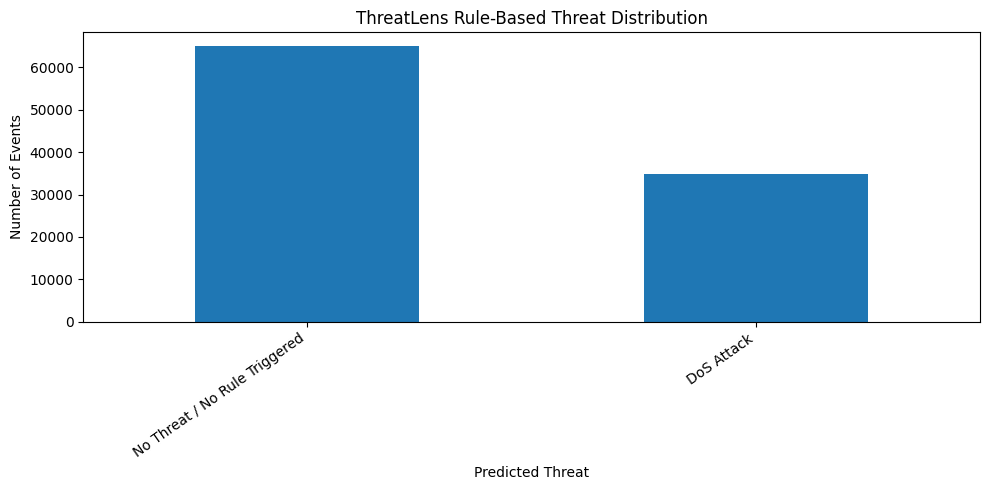

In [ ]:

counts = threat_results["Predicted_Threat"].value_counts()

plt.figure(figsize=(10, 5))
counts.plot(kind="bar")
plt.title("ThreatLens Rule-Based Threat Distribution")
plt.xlabel("Predicted Threat")
plt.ylabel("Number of Events")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



# 15. Evaluate Against the Dataset Label

If the uploaded dataset contains a label column, this section compares the rule-engine output with that label.

Because datasets use different naming conventions, the notebook performs a lightweight label normalization into broad threat categories.

**Important:** This evaluation is only an assessment of the rule system against the dataset labels. It does not feed the labels into the rule engine.


In [ ]:

def normalize_label(label):
    s = str(label).strip().lower()

    if s in {"nan", "none", ""}:
        return "Unknown"

    if any(x in s for x in ["ddos", "distributed denial"]):
        return "DDoS Attack"

    if any(x in s for x in ["dos", "denial of service", "slowloris", "slowhttptest", "hulk"]):
        return "DoS Attack"

    if any(x in s for x in ["brute", "patator", "credential", "password", "ssh"]):
        return "Brute Force Attack"

    if any(x in s for x in ["portscan", "port scan", "scan"]):
        return "Port Scan"

    if any(x in s for x in ["benign", "normal", "benign traffic"]):
        return "Normal"

    return "Other Attack"

if LABEL_COL:
    eval_df = threat_results[[LABEL_COL, "Predicted_Threat"]].copy()
    eval_df["True_Category"] = eval_df[LABEL_COL].map(normalize_label)

    # Align the normal class naming
    pred = eval_df["Predicted_Threat"].replace({
        "No Threat / No Rule Triggered": "Normal"
    })

    eval_df["Predicted_Category"] = pred

    print("Normalized evaluation labels:")
    display(eval_df["True_Category"].value_counts().to_frame("count"))

    print("Rule-based predicted categories:")
    display(eval_df["Predicted_Category"].value_counts().to_frame("count"))

    # Confusion matrix without requiring sklearn
    categories = sorted(set(eval_df["True_Category"]) | set(eval_df["Predicted_Category"]))
    cm = pd.crosstab(
        eval_df["True_Category"],
        eval_df["Predicted_Category"],
        rownames=["Actual"],
        colnames=["Predicted"],
        dropna=False
    ).reindex(index=categories, columns=categories, fill_value=0)

    print("\nConfusion matrix:")
    display(cm)

    accuracy = (eval_df["True_Category"] == eval_df["Predicted_Category"]).mean()
    print(f"Broad-category rule accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
else:
    print("No label column was detected, so automatic evaluation is not available.")


Normalized evaluation labels:


,count
True_Category,
Normal,100000


Rule-based predicted categories:


,count
Predicted_Category,
Normal,65038
DoS Attack,34962



Confusion matrix:


Predicted,DoS Attack,Normal
Actual,,
DoS Attack,0,0
Normal,34962,65038


Broad-category rule accuracy: 0.6504 (65.04%)



# 16. Explain One Prediction

This section produces a presentation-ready decision path.

The output format is:

`Input facts → Rule fired → Threat → Risk → Explanation`


In [ ]:

# Show the first event for which a threat rule fired, if one exists.
threat_rows = threat_results[
    threat_results["Predicted_Threat"] != "No Threat / No Rule Triggered"
]

if len(threat_rows):
    sample = threat_rows.iloc[0]

    print("========== ThreatLens Decision Explanation ==========")
    print("Predicted Threat :", sample["Predicted_Threat"])
    print("Risk Level       :", sample["Risk_Level"])
    print("Rule ID          :", sample["Fired_Rule_ID"])
    print("Rule Name        :", sample["Fired_Rule_Name"])
    print("Rule Path        :", sample["Fired_Rule_Path"])
    print("Source IP        :", sample["Source_IP"])
    print("Destination Port :", sample["Destination_Port"])
    print("Flow Duration    :", sample["Flow_Duration"])
    print("Total Packets    :", sample["Total_Packets"])
    print("Packet Rate      :", sample["Packet_Rate"])
    print("Explanation      :", sample["Explanation"])
else:
    print("No threat rule fired in the processed sample.")


========== ThreatLens Decision Explanation ==========
Predicted Threat : DoS Attack
Risk Level       : High
Rule ID          : R007
Rule Name        : DoS Detection
Rule Path        : R003 → R007
Source IP        : None
Destination Port : nan
Flow Duration    : 4
Total Packets    : 2
Packet Rate      : 500000.0
Explanation      : The event shows unusually high traffic volume/rate and satisfies the flooding rule.



# 17. Export Results

The notebook creates files that can be submitted as evidence for Task 2:

- `ThreatLens_Rule_Results.csv` — row-level predictions and explanations
- `ThreatLens_Rule_Base.csv` — formal IF–THEN rule table
- `ThreatLens_Rule_Summary.csv` — rule firing summary
- `ThreatLens_Task2_Test_Cases.csv` — five manual test cases


In [ ]:

# Export row-level rule results
results_path = "/content/ThreatLens_Rule_Results.csv"
threat_results.to_csv(results_path, index=False)

# Export rule base
rule_base_path = "/content/ThreatLens_Rule_Base.csv"
rules_df.to_csv(rule_base_path, index=False)

# Export rule summary
summary_path = "/content/ThreatLens_Rule_Summary.csv"
rule_summary.to_csv(summary_path, index=False)

# Export manual test cases
manual_cases = [
    ("Test 1", "Authentication / Brute Force", test1),
    ("Test 2", "Port Scan", test2),
    ("Test 3", "DoS", test3),
    ("Test 4", "DDoS", test4),
    ("Test 5", "Normal", test5),
]

test_rows = []
for name, description, facts in manual_cases:
    result, _, fired = forward_chain(facts)
    test_rows.append({
        "Test_Case": name,
        "Description": description,
        "Fired_Rules": " → ".join(x["rule_id"] for x in fired) if fired else "R008",
        "Predicted_Threat": result["threat"],
        "Risk_Level": result["risk"],
        "Explanation": result["explanation"]
    })

test_cases_df = pd.DataFrame(test_rows)
test_cases_path = "/content/ThreatLens_Task2_Test_Cases.csv"
test_cases_df.to_csv(test_cases_path, index=False)

print("Files created:")
for p in [results_path, rule_base_path, summary_path, test_cases_path]:
    print("-", p)


Files created:
- /content/ThreatLens_Rule_Results.csv
- /content/ThreatLens_Rule_Base.csv
- /content/ThreatLens_Rule_Summary.csv
- /content/ThreatLens_Task2_Test_Cases.csv



# 18. Download the Task 2 Outputs

Run the next cell to download the generated CSV files.


In [ ]:

from google.colab import files

files.download("/content/ThreatLens_Rule_Base.csv")
files.download("/content/ThreatLens_Rule_Summary.csv")
files.download("/content/ThreatLens_Task2_Test_Cases.csv")
files.download("/content/ThreatLens_Rule_Results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# 19. Task 2 Conclusion

### Decision-making logic
ThreatLens uses a collection of IF–THEN rules to identify suspicious cybersecurity behavior from security-log features.

### Inference mechanism
**Forward chaining** is used because the reasoning starts with observed facts from the security log and progressively derives intermediate facts and final threat conclusions.

### Knowledge base
The knowledge base consists of:
- security-event facts,
- derived security indicators,
- threat rules,
- risk levels,
- explanations.

### Explainability
For every rule-based decision, ThreatLens records:
- the rule ID,
- the rule name,
- the fired-rule path,
- the resulting threat,
- the risk level,
- the explanation.

### Validation
The rule engine is tested using five sample cases and can additionally be evaluated against the uploaded dataset's labels when a label column is available.
